In [1]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt

from src.run.model.run_segment_cnn_classifier import RunSegmentCNN
from src.run.preprocess.config import _project_path

In [ ]:
# =====================================
# Dipendenze
# =====================================
import os
from contextlib import redirect_stdout
from itertools import product

import pandas as pd
import torch
import matplotlib.pyplot as plt

# =====================================
# 1. Esperimento: grid search con cross-validation
#    (ogni combinazione esegue la CV a 5 fold su tutto il dataset,
#     scelta sulla media dei fold di validazione all'ultima epoca)
# =====================================
param_grid = {
    "window_size": [128, 256, 512, 1024],
    "learning_rate": [1e-6, 1e-5, 1e-4, 1e-3],
    "regularization": [1e-6, 1e-5, 1e-4, 1e-3],
    "batch_size": [8, 16],
}
epoch_values = [25, 50, 100]   # lette dalla stessa run da 100 epoche: non moltiplicano gli addestramenti

metrics = ["accuracy", "f1", "auc", "precision", "recall", "specificity"]
param_keys = list(param_grid) + ["epochs"]

out_dir = _project_path("experiments/test_iperparametri/cnn1D(train seg - val no)/grid_search_cv")
out_dir.mkdir(parents=True, exist_ok=True)
csv_path = out_dir / "grid_search_results.csv"

# Ripresa: combinazioni già completate in una sessione precedente
results = pd.read_csv(csv_path).to_dict("records") if csv_path.exists() else []
done = {tuple(r[k] for k in param_grid) for r in results}

combos = list(product(*param_grid.values()))
print(f"Grid search: {len(combos)} combinazioni x 5 fold = {len(combos) * 5} addestramenti "
      f"({len(done)} combinazioni già completate)")

for i, values in enumerate(combos, 1):
    params = dict(zip(param_grid, values))
    if tuple(values) in done:
        continue

    runner = RunSegmentCNN(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
        tasks=[1],
        feature_names=("x", "y"),
        engineered_features=(),
        epochs=max(epoch_values),
        n_splits=5,
        normalize=True,
        seed=42,
        device="cuda" if torch.cuda.is_available() else "cpu",
        aggregation="mean",
        output_dir=None,                       # non salva i file di ogni singola run
        training_cfg={
            "metrics": metrics,
            "monitor_metric": "auc",
            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,
        },
        **params,
    )

    with open(os.devnull, "w") as devnull, redirect_stdout(devnull):   # niente stampe per epoca
        summary = runner.run()

    # Media sui 5 fold delle metriche di validazione all'epoca indicata
    for e in epoch_values:
        row = {**params, "epochs": e}
        for m in metrics:
            row[m] = sum(f["history"][e - 1][f"val_{m}"] for f in summary["folds"]) / len(summary["folds"])
        results.append(row)

    pd.DataFrame(results).to_csv(csv_path, index=False)   # salva dopo ogni combinazione
    print(f"{i}/{len(combos)} {params} | " + " | ".join(
        f"ep {r['epochs']}: acc {r['accuracy']:.3f}, auc {r['auc']:.3f}" for r in results[-len(epoch_values):]
    ))

# =====================================
# 2. Tabella riassuntiva e combinazione scelta
#    (accuracy media più alta, a parità AUC)
# =====================================
df = (
    pd.DataFrame(results)
    .sort_values(["accuracy", "auc"], ascending=False)
    .reset_index(drop=True)
)

print("\n=== Prime 10 combinazioni (media sui 5 fold) ===")
print(df.head(10).round(4).to_string(index=False))

best = df.iloc[0]
best_params = {k: (int(best[k]) if k in ("window_size", "batch_size", "epochs") else float(best[k])) for k in param_keys}
print("\n=== Iperparametri scelti ===")
print(best_params)
print({m: round(best[m], 4) for m in metrics})

# =====================================
# 3. Grafico: accuracy media per valore di ciascun iperparametro
#    (media sulle combinazioni con quel valore)
# =====================================
fig, axes = plt.subplots(1, len(param_keys), figsize=(4 * len(param_keys), 4), sharey=True)

for ax, k in zip(axes, param_keys):
    g = df.groupby(k)[["accuracy", "auc"]].mean()
    labels = [f"{v:.0e}" if k in ("learning_rate", "regularization") else str(int(v)) for v in g.index]
    ax.plot(labels, g["accuracy"], marker="o", linewidth=2, label="accuracy")
    ax.plot(labels, g["auc"], marker="s", linewidth=2, label="AUC")
    ax.set_title(k)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Media sulle combinazioni (5 fold, ultima epoca)")
axes[0].legend()
plt.suptitle("Grid search con CV: effetto di ciascun iperparametro")
plt.tight_layout()
plt.show()

# =====================================
# 4. Run finale con gli iperparametri scelti (salva i risultati per fold)
# =====================================
runner = RunSegmentCNN(
    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
    tasks=[1],
    feature_names=("x", "y"),
    engineered_features=(),
    n_splits=5,
    normalize=True,
    seed=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
    aggregation="mean",
    output_dir=out_dir / "best_configuration",
    training_cfg={
        "metrics": metrics,
        "monitor_metric": "auc",
        "early_stopping_patience": float("inf"),
        "min_delta": 0.0,
        "results_writer": "csv",
        "save_metrics": True,
    },
    **best_params,
)
summary = runner.run()
print({m: round(summary["averages"][f"last_val_{m}"], 4) for m in metrics})

Grid search: 128 combinazioni x 5 fold = 640 addestramenti (0 combinazioni già completate)
1/128 {'window_size': 128, 'learning_rate': 1e-06, 'regularization': 1e-06, 'batch_size': 8} | ep 25: acc 0.529, auc 0.684 | ep 50: acc 0.529, auc 0.678 | ep 100: acc 0.514, auc 0.596
2/128 {'window_size': 128, 'learning_rate': 1e-06, 'regularization': 1e-06, 'batch_size': 16} | ep 25: acc 0.529, auc 0.685 | ep 50: acc 0.529, auc 0.662 | ep 100: acc 0.514, auc 0.630
3/128 {'window_size': 128, 'learning_rate': 1e-06, 'regularization': 1e-05, 'batch_size': 8} | ep 25: acc 0.529, auc 0.684 | ep 50: acc 0.529, auc 0.678 | ep 100: acc 0.514, auc 0.596
4/128 {'window_size': 128, 'learning_rate': 1e-06, 'regularization': 1e-05, 'batch_size': 16} | ep 25: acc 0.529, auc 0.685 | ep 50: acc 0.529, auc 0.662 | ep 100: acc 0.514, auc 0.630
5/128 {'window_size': 128, 'learning_rate': 1e-06, 'regularization': 0.0001, 'batch_size': 8} | ep 25: acc 0.529, auc 0.684 | ep 50: acc 0.529, auc 0.678 | ep 100: acc 0.5


FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6763 | train_accuracy=0.5736 | train_f1=0.6743 | train_auc=0.5816 | train_precision=0.6025 | train_recall=0.7656 | train_specificity=0.3121 | val_loss=0.6636 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.3571 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6510 | train_accuracy=0.5541 | train_f1=0.6761 | train_auc=0.5872 | train_precision=0.5816 | train_recall=0.8073 | train_specificity=0.2092 | val_loss=0.6566 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.4107 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.6379 | train_accuracy=0.5736 | train_f1=0.6940 | train_auc=0.6351 | train_precision=0.5919 | train_recall=0.8385 | train_specificity=0.2128 | val_loss=0.6593 | val_accuracy=0.3333 | val_f1=0.3750 | val_auc=0.3750 | val_precision=0.3750 | val_recall=0.3750 | val_specificity=0.2857
F

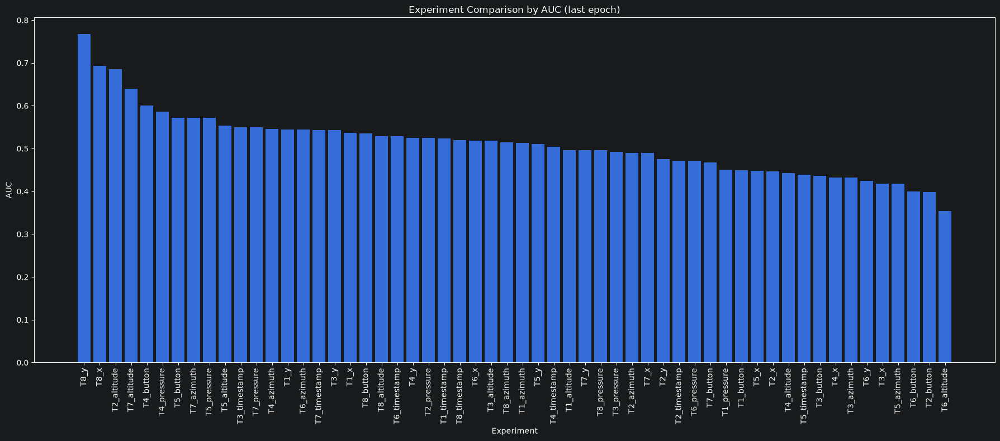

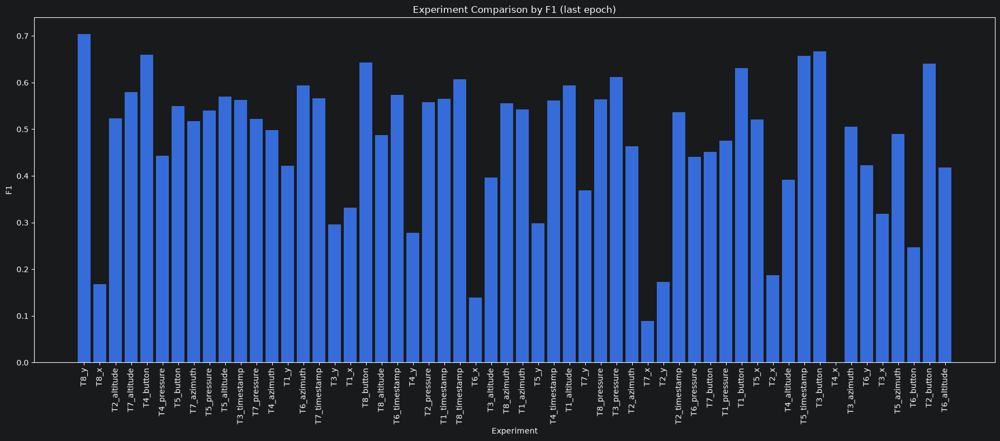

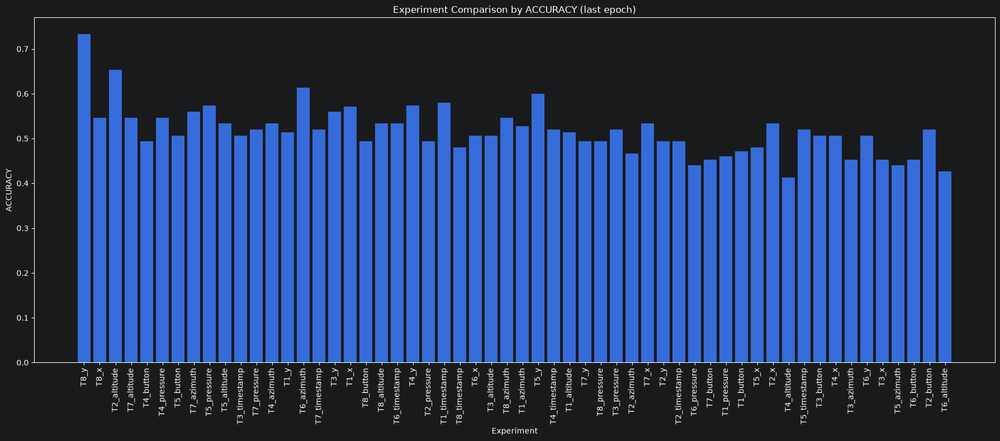

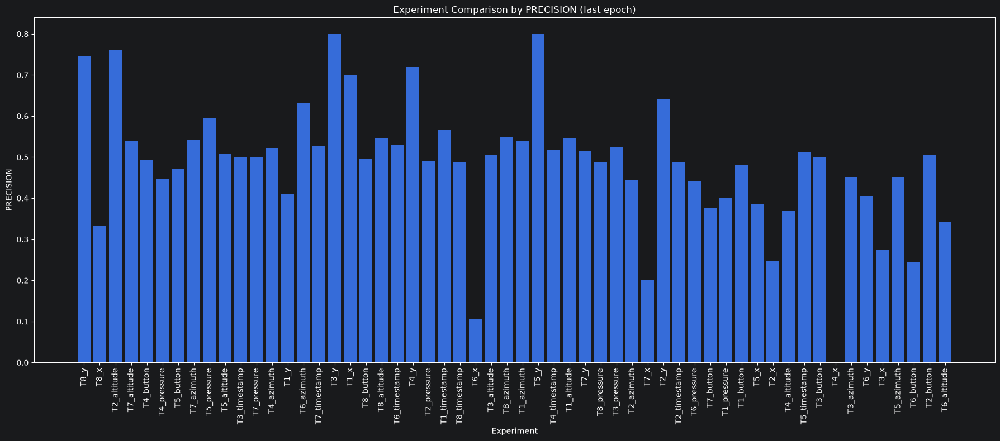

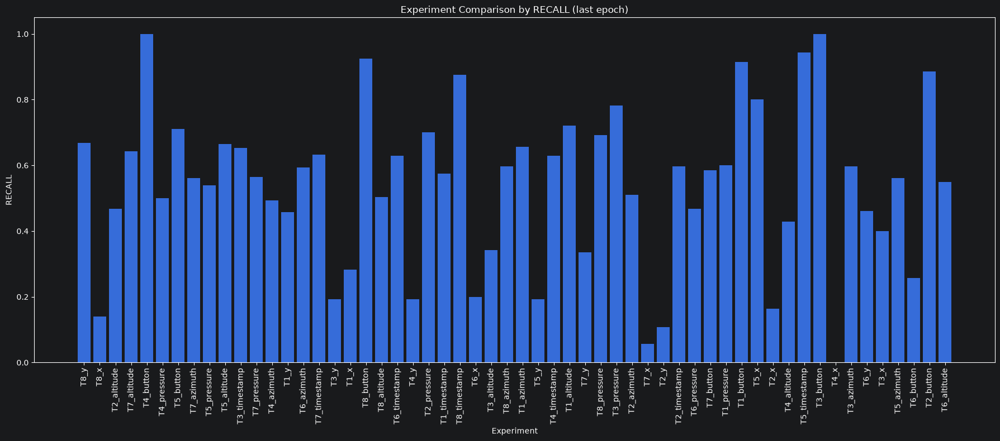


=== BEST EXPERIMENT (last epoch) ===
Task: 8
Feature: y
AUC: 0.7679
F1: 0.7042
Accuracy: 0.7333


In [8]:
# Experiments for cnn1D (one feature -> one task)

features = ["x", "y", "button", "timestamp", "azimuth", "altitude", "pressure"]
tasks = [1, 2, 3, 4, 5, 6, 7, 8]
results = []

for t in tasks:
    for f in features:
        if f == "x" or f == "y":

            runner = RunSegmentCNN(
                    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                    tasks=[t],
                    feature_names=(f,),
                    engineered_features=(),
                    window_size=256,
                    epochs=50,
                    batch_size=16,
                    learning_rate=1e-3,
                    regularization=1e-3,
                    n_splits=5,
                    normalize=True,
                    device="cuda" if torch.cuda.is_available() else "cpu",
                    aggregation="mean",
                    output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}_coordinate"),
                    training_cfg={
                        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                        "monitor_metric": "auc",
                        "early_stopping_patience": float("inf"),
                        "min_delta": 0.0,
                        "results_writer": "csv",
                        "save_metrics": True,
                    }
                )
        else:
            runner = RunSegmentCNN(
                    data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                    metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                    tasks=[t],
                    feature_names=(f,),
                    engineered_features=(),
                    window_size=256,
                    epochs=50,
                    batch_size=16,
                    learning_rate=1e-3,
                    regularization=1e-3,
                    n_splits=5,
                    normalize=True,
                    device="cuda" if torch.cuda.is_available() else "cpu",
                    aggregation="mean",
                    output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}"),
                    training_cfg={
                        "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                        "monitor_metric": "auc",
                        "early_stopping_patience": float("inf"),
                        "min_delta": 0.0,
                        "results_writer": "csv",
                        "save_metrics": True,
                    }
                )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": t,
            "feature": f,
            "accuracy": averages["last_val_accuracy"],
            "f1": averages["last_val_f1"],
            "auc": averages["last_val_auc"],
            "precision": averages["last_val_precision"],
            "recall": averages["last_val_recall"],
            "specificity": averages["last_val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC (ultima epoca)
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS (last epoch) ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1 (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT PRECISION
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["precision"])

plt.xticks(rotation=90)
plt.ylabel("PRECISION")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by PRECISION (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT RECALL
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["recall"])

plt.xticks(rotation=90)
plt.ylabel("RECALL")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by RECALL (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT (last epoch) ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 57
Validation patients: 15
Fold 01 | Epoch 01 | train_loss=0.6681 | train_accuracy=0.6006 | train_f1=0.6756 | train_auc=0.6104 | train_precision=0.6353 | train_recall=0.7214 | train_specificity=0.4362 | val_loss=0.7324 | val_accuracy=0.5333 | val_f1=0.6316 | val_auc=0.4464 | val_precision=0.5455 | val_recall=0.7500 | val_specificity=0.2857
Fold 01 | Epoch 02 | train_loss=0.6011 | train_accuracy=0.6411 | train_f1=0.6591 | train_auc=0.7012 | train_precision=0.7287 | train_recall=0.6016 | train_specificity=0.6950 | val_loss=0.7566 | val_accuracy=0.4667 | val_f1=0.6000 | val_auc=0.2679 | val_precision=0.5000 | val_recall=0.7500 | val_specificity=0.1429
Fold 01 | Epoch 03 | train_loss=0.5666 | train_accuracy=0.6652 | train_f1=0.7070 | train_auc=0.7516 | train_precision=0.7135 | train_recall=0.7005 | train_specificity=0.6170 | val_loss=0.7931 | val_accuracy=0.4000 | val_f1=0.3077 | val_auc=0.2679 | val_precision=0.4000 | val_recall=0.2500 | val_specificity=0.5714
F

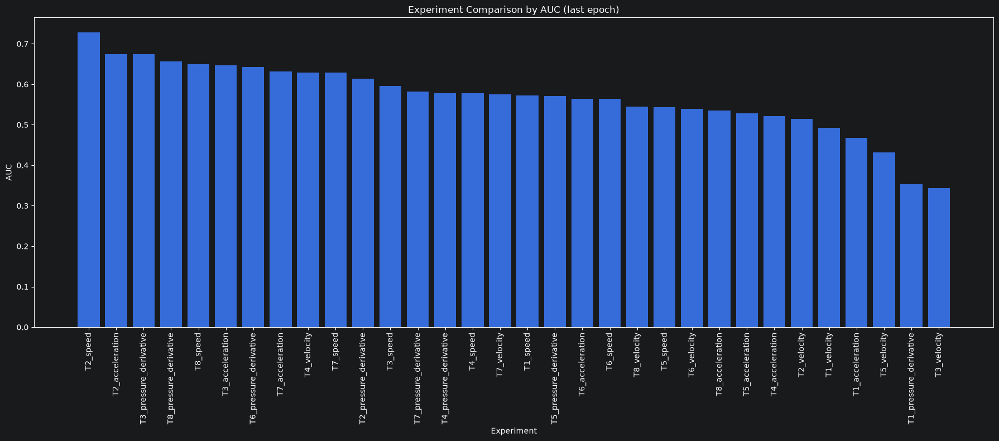

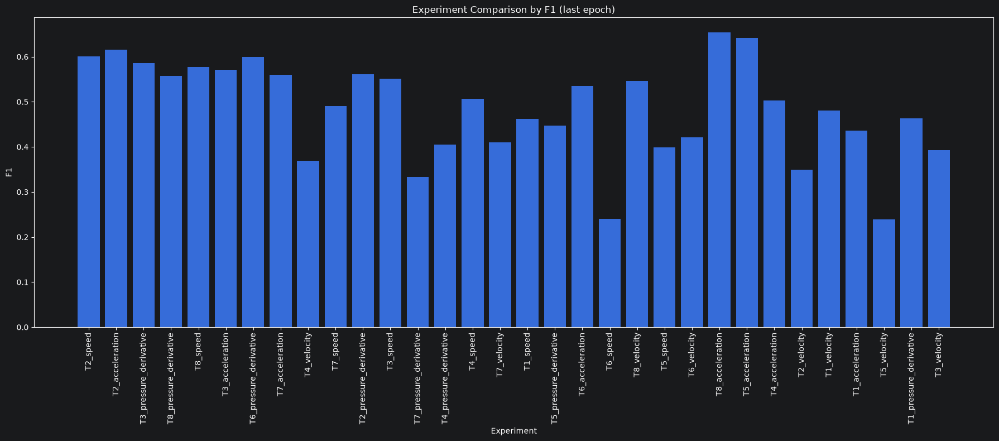


=== BEST EXPERIMENT (last epoch) ===
Task: 2
Feature: speed
AUC: 0.7286
F1: 0.6012
Accuracy: 0.6133


In [11]:
# Experiments for cnn1D with engineering features

features = ["speed", "acceleration", "velocity", "pressure_derivative"]
task = [1, 2, 3, 4, 5, 6, 7, 8]
results = []

for t in task:
    for f in features:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[t],
                feature_names=(),
                engineered_features=(f,),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_{t}/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": t,
            "feature": f,
            "accuracy": averages["last_val_accuracy"],
            "f1": averages["last_val_f1"],
            "auc": averages["last_val_auc"],
            "precision": averages["last_val_precision"],
            "recall": averages["last_val_recall"],
            "specificity": averages["last_val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC (ultima epoca)
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS (last epoch) ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1 (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT (last epoch) ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")

Combinazioni di feature derivate (inclusa quella vuota): 16
Numero totale di configurazioni: 48

Task: 8 | Feature: x (sola)
  -> gi﷿﷿﷿﷿﷿﷿ eseguito, leggo summary.csv

Task: 8 | Feature: x + acceleration

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6425 | train_accuracy=0.6662 | train_f1=0.6720 | train_auc=0.6941 | train_precision=0.6693 | train_recall=0.6747 | train_specificity=0.6575 | val_loss=0.6375 | val_accuracy=0.7333 | val_f1=0.7143 | val_auc=0.7500 | val_precision=0.8333 | val_recall=0.6250 | val_specificity=0.8571
Fold 01 | Epoch 02 | train_loss=0.6270 | train_accuracy=0.6935 | train_f1=0.6871 | train_auc=0.6993 | train_precision=0.7118 | train_recall=0.6640 | train_specificity=0.7238 | val_loss=0.6151 | val_accuracy=0.7333 | val_f1=0.7143 | val_auc=0.6607 | val_precision=0.8333 | val_recall=0.6250 | val_s

,task,base,derived,feature,accuracy,f1,auc,precision,recall,specificity
0,8,y,speed+velocity+pressure_derivative,y_speed_velocity_pressure_derivative,0.7867,0.7447,0.8143,0.8933,0.6429,0.9250
1,8,y,speed,y_speed,0.7600,0.7174,0.7893,0.8214,0.6429,0.8714
2,8,x,acceleration+pressure_derivative,x_acceleration_pressure_derivative,0.7600,0.7112,0.7857,0.8548,0.6179,0.8929
3,8,y,speed+velocity,y_speed_velocity,0.7467,0.7005,0.7607,0.7843,0.6429,0.8429
4,8,y,acceleration+speed+velocity+pressure_derivative,y_acceleration_speed_velocity_pressure_derivative,0.7333,0.6654,0.7929,0.8314,0.5607,0.8964
5,8,y,-,y_coordinate,0.7333,0.7042,0.7679,0.7464,0.6679,0.7929
6,8,xy,-,xy_coordinate,0.7333,0.6869,0.7429,0.7593,0.6393,0.8179
7,8,y,acceleration+speed+velocity,y_acceleration_speed_velocity,0.7200,0.6594,0.7929,0.7629,0.5857,0.8429
8,8,y,velocity,y_velocity,0.7200,0.6695,0.7821,0.7833,0.5893,0.8464
9,8,xy,acceleration,xy_acceleration,0.7200,0.6850,0.7750,0.7476,0.6429,0.7893



=== ACCURACY (last epoch) ===


base,x,y,xy
derived,,,
-,0.547,0.733,0.733
acceleration,0.600,0.680,0.720
speed,0.693,0.760,0.707
velocity,0.573,0.720,0.707
pressure_derivative,0.693,0.707,0.653
acceleration+speed,0.680,0.707,0.693
acceleration+velocity,0.640,0.680,0.720
acceleration+pressure_derivative,0.760,0.693,0.667
speed+velocity,0.720,0.747,0.693



=== AUC (last epoch) ===


base,x,y,xy
derived,,,
-,0.693,0.768,0.743
acceleration,0.714,0.736,0.775
speed,0.757,0.789,0.739
velocity,0.525,0.782,0.750
pressure_derivative,0.732,0.761,0.736
acceleration+speed,0.736,0.757,0.771
acceleration+velocity,0.707,0.761,0.757
acceleration+pressure_derivative,0.786,0.754,0.743
speed+velocity,0.750,0.761,0.754



=== MIGLIORE COMBINAZIONE PER CIASCUNA BASE (last epoch) ===


,base,derived,accuracy,f1,auc,precision,recall,specificity
0,x,acceleration+pressure_derivative,0.7600,0.7112,0.7857,0.8548,0.6179,0.8929
1,xy,-,0.7333,0.6869,0.7429,0.7593,0.6393,0.8179
2,y,speed+velocity+pressure_derivative,0.7867,0.7447,0.8143,0.8933,0.6429,0.9250


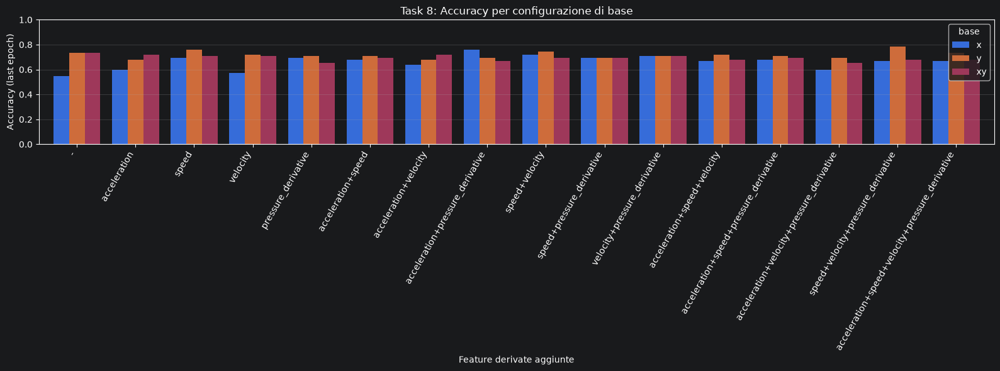

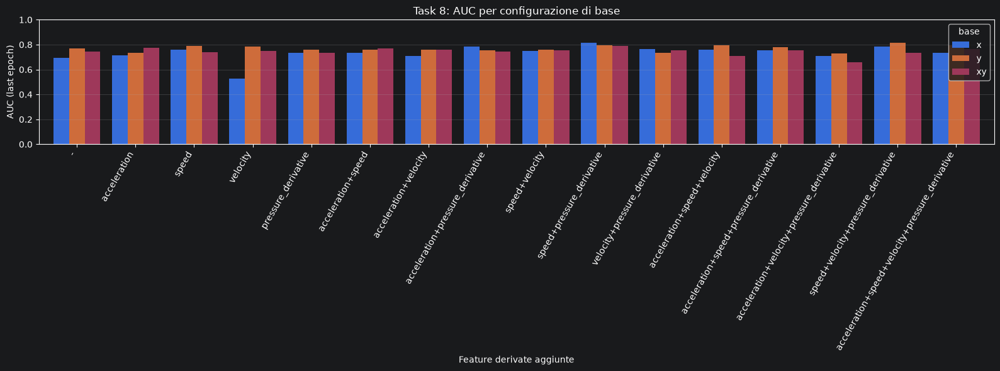


=== BEST CONFIGURATION (last epoch) ===
Task: 8
Base: y
Feature derivate: speed+velocity+pressure_derivative
accuracy    : 0.7867
f1          : 0.7447
auc         : 0.8143
precision   : 0.8933
recall      : 0.6429
specificity : 0.9250


In [12]:
# ============================================================
# CNN1D: x, y e (x,y) + TUTTE LE COMBINAZIONI DI
# FEATURE DERIVATE, SUL TASK 8 (metriche all'ultima epoca)
# ============================================================

import itertools
from pathlib import Path

# ============================================================
# CONFIGURAZIONE
# ============================================================

task = 8

# configurazioni di base: nome -> feature acquisite
base_configs = {
    "x": ("x",),
    "y": ("y",),
    "xy": ("x", "y"),
}

feature_eng = [
    "acceleration",
    "speed",
    "velocity",
    "pressure_derivative",
]

# sottoinsieme vuoto (base da sola) + tutte le combinazioni non vuote
feature_combinations = [()]
for r in range(1, len(feature_eng) + 1):
    feature_combinations.extend(itertools.combinations(feature_eng, r))

metric_names = ["accuracy", "f1", "auc", "precision", "recall", "specificity"]

print(f"Combinazioni di feature derivate (inclusa quella vuota): {len(feature_combinations)}")
print(f"Numero totale di configurazioni: {len(base_configs) * len(feature_combinations)}")


def folder_name(base: str, combo: tuple) -> str:
    """Stesso schema di nomi delle cartelle gi﷿﷿﷿﷿﷿﷿ esistenti."""
    if not combo:
        return f"{base}_coordinate"          # x_coordinate, y_coordinate, xy_coordinate
    return f"{base}_{'_'.join(combo)}"       # es. y_speed_pressure_derivative


# ============================================================
# ESPERIMENTI
# ============================================================

results = []

for base, base_features in base_configs.items():

    for combo in feature_combinations:

        name = folder_name(base, combo)
        output_dir = _project_path(
            f"experiments/ant/cnn1D/"
            f"raw_segment(train_seg - val_no)/"
            f"Task_{task}/{name}"
        )

        print("\n" + "=" * 80)
        print(f"Task: {task} | Feature: {base}" + (f" + {', '.join(combo)}" if combo else " (sola)"))
        print("=" * 80)

        summary_path = Path(output_dir) / "summary.csv"

        # se l'esperimento ﷿﷿﷿﷿﷿﷿ gi﷿﷿﷿﷿﷿﷿ stato eseguito (es. x o y da sole nel passo 1), lo rilegge
        if summary_path.exists():
            print("  -> gi﷿﷿﷿﷿﷿﷿ eseguito, leggo summary.csv")
            averages = pd.read_csv(summary_path).iloc[0].to_dict()

        else:
            runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),

                tasks=[task],

                # feature acquisite della configurazione di base
                feature_names=base_features,

                # combinazione corrente di feature derivate
                engineered_features=combo,

                # iperparametri selezionati
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,

                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=output_dir,

                training_cfg={
                    "metrics": metric_names,
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                },
            )

            summary = runner.run()
            averages = summary["averages"]

        row = {
            "task": task,
            "base": base,
            "derived": "+".join(combo) if combo else "-",
            "feature": name,
        }
        row.update({m: averages[f"last_val_{m}"] for m in metric_names})
        results.append(row)


# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(results)

df.to_csv("cnn1d_step3_task8_combinations.csv", index=False)

print("\n" + "=" * 80)
print("ESPERIMENTI COMPLETATI")
print("=" * 80)
print(f"Configurazioni: {len(df)}")

# criterio della tesi: accuracy, a parit﷿﷿﷿﷿﷿﷿ AUC
df_sorted = df.sort_values(by=["accuracy", "auc"], ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("TOP 15 CONFIGURAZIONI (last epoch) - accuracy, a parit﷿﷿﷿﷿﷿﷿ AUC")
print("=" * 80)
display(df_sorted.head(15).round(4))


# ============================================================
# TABELLE PER LA TESI: righe = feature derivate, colonne = base
# ============================================================

order = ["-"] + ["+".join(c) for c in feature_combinations[1:]]

acc_table = df.pivot(index="derived", columns="base", values="accuracy").reindex(order)[["x", "y", "xy"]]
auc_table = df.pivot(index="derived", columns="base", values="auc").reindex(order)[["x", "y", "xy"]]

print("\n=== ACCURACY (last epoch) ===")
display(acc_table.round(3))

print("\n=== AUC (last epoch) ===")
display(auc_table.round(3))


# ============================================================
# MIGLIORE CONFIGURAZIONE PER CIASCUNA BASE
# ============================================================

best_per_base = (
    df.sort_values(["base", "accuracy", "auc"], ascending=[True, False, False])
      .groupby("base", as_index=False)
      .first()
)

print("\n=== MIGLIORE COMBINAZIONE PER CIASCUNA BASE (last epoch) ===")
display(best_per_base[["base", "derived", *metric_names]].round(4))


# ============================================================
# PLOT - ACCURACY E AUC PER BASE
# ============================================================

for metric, table in [("Accuracy", acc_table), ("AUC", auc_table)]:

    ax = table.plot(kind="bar", figsize=(16, 6), width=0.8)
    ax.set_xlabel("Feature derivate aggiunte")
    ax.set_ylabel(f"{metric} (last epoch)")
    ax.set_title(f"Task {task}: {metric} per configurazione di base")
    ax.set_ylim(0, 1)
    ax.grid(True, axis="y", alpha=0.3)
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()


# ============================================================
# BEST EXPERIMENT
# ============================================================

best = df_sorted.iloc[0]

print("\n=== BEST CONFIGURATION (last epoch) ===")
print(f"Task: {best['task']}")
print(f"Base: {best['base']}")
print(f"Feature derivate: {best['derived']}")
for m in metric_names:
    print(f"{m:12s}: {best[m]:.4f}")

In [14]:
# Experiments for cnn1D (one feature -> all task)

features = ["x", "y", "button", "azimuth", "timestamp", "altitude", "pressure"]
results = []


for f in features:
    if f == "x" or f == "y":

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(f,),
                engineered_features=(),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}_coordinate"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )
    else:
        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(f,),
                engineered_features=(),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
            )

    summary = runner.run()

    averages = summary["averages"]

    results.append({
        "task": "all",
        "feature": f,
        "accuracy": averages["last_val_accuracy"],
        "f1": averages["last_val_f1"],
        "auc": averages["last_val_auc"],
        "precision": averages["last_val_precision"],
        "recall": averages["last_val_recall"],
        "specificity": averages["last_val_specificity"],
    })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC (ultima epoca)
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS (last epoch) ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1 (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT (last epoch) ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6958 | train_accuracy=0.5059 | train_f1=0.6138 | train_auc=0.5083 | train_precision=0.5152 | train_recall=0.7591 | train_specificity=0.2346 | val_loss=0.6929 | val_accuracy=0.4667 | val_f1=0.6364 | val_auc=0.6250 | val_precision=0.5000 | val_recall=0.8750 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6907 | train_accuracy=0.5379 | train_f1=0.6439 | train_auc=0.5332 | train_pre

KeyboardInterrupt: 

In [ ]:
# Experiments for cnn1D (one feature_eng -> all tasks)

feature = ["speed", "velocity", "acceleration", "pressure_derivative"]
results = []

for f in feature:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[1, 2, 3, 4, 5, 6, 7, 8],
                feature_names=(),
                engineered_features=(f,),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_all/{f}"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": "all",
            "feature": f,
            "accuracy": averages["last_val_accuracy"],
            "f1": averages["last_val_f1"],
            "auc": averages["last_val_auc"],
            "precision": averages["last_val_precision"],
            "recall": averages["last_val_recall"],
            "specificity": averages["last_val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC (ultima epoca)
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS (last epoch) ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC (last epoch)")

plt.tight_layout()
plt.show()


# =========================
# PLOT ACCURACY
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["accuracy"])

plt.xticks(rotation=90)
plt.ylabel("ACCURACY")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by ACCURACY (last epoch)")

plt.tight_layout()
plt.show()
# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1 (last epoch)")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT (last epoch) ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7012 | train_accuracy=0.5266 | train_f1=0.5627 | train_auc=0.5212 | train_precision=0.5415 | train_recall=0.5856 | train_specificity=0.4626 | val_loss=0.6801 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.8036 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6688 | train_accuracy=0.5884 | train_f1=0.6525 | train_auc=0.6158 | train_precision=0.5816 | train_recall=0.7431 | train_specificity=0.4207 | val_loss=0.6041 | val_accuracy=0.8000 | val_f1=0.7692 | val_auc=0.8214 | val_precision=1.0000 | val_recall=0.6250 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6521 | train_accuracy=0.6099 | train_f1=0.6591 | train_auc=0.6575 | train_precision=0.6041 | train_recall=0.7251 | train_specificity=0.4850 | val_loss=0

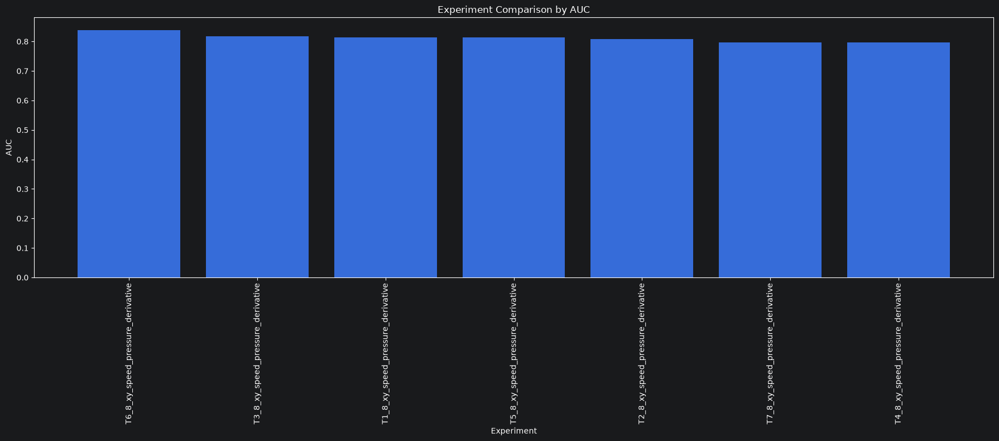

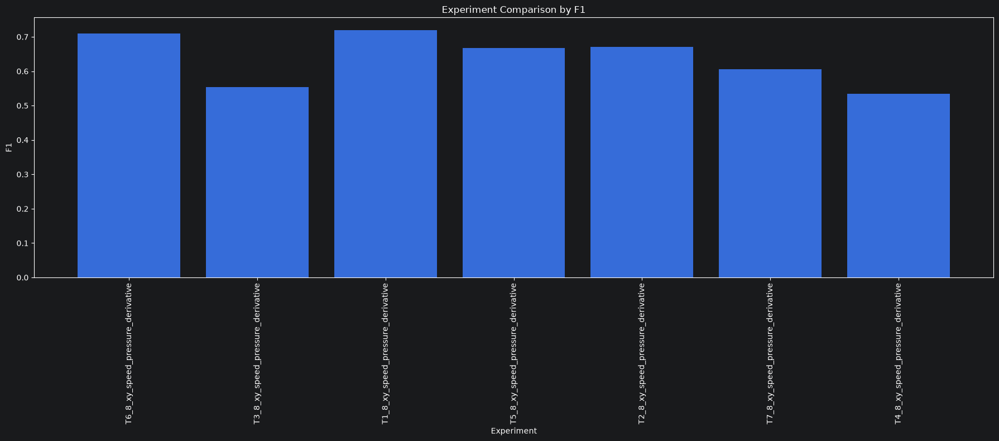


=== BEST EXPERIMENT ===
Task: 6_8
Feature: xy_speed_pressure_derivative
AUC: 0.8393
F1: 0.7095
Accuracy: 0.7467


In [15]:
 # Experiments for cnn1D

task = [1, 2, 3, 4, 5, 6, 7]
results = []

for t in task:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=[t, 8],
                feature_names=("y",),
                engineered_features=("speed", "velocity", "pressure_derivative",),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path(f"experiments/ant/cnn1D/raw_segment + cnn(train_seg - val_no)/Task_{t}_8/xy_pressure_derivative"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": f"{t}_8",
            "feature": "xy_speed_pressure_derivative",
            "accuracy": averages["last_val_accuracy"],
            "f1": averages["last_val_f1"],
            "auc": averages["last_val_auc"],
            "precision": averages["last_val_precision"],
            "recall": averages["last_val_recall"],
            "specificity": averages["last_val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00005__2_1.svc: expected 1396, found 1344.
[WARNING] Mismatch in 00010__2_1.svc: expected 2114, found 2111.
[WARNING] Mismatch in 00051__5_1.svc: expected 1870, found 1620.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.6957 | train_accuracy=0.5102 | train_f1=0.6478 | train_auc=0.5047 | train_precision=0.5157 | train_recall=0.8710 | train_specificity=0.1236 | val_loss=0.6851 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6607 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.6909 | train_accuracy=0.5202 | train_f1=0.5869 | train_auc=0.5288 | train_pre

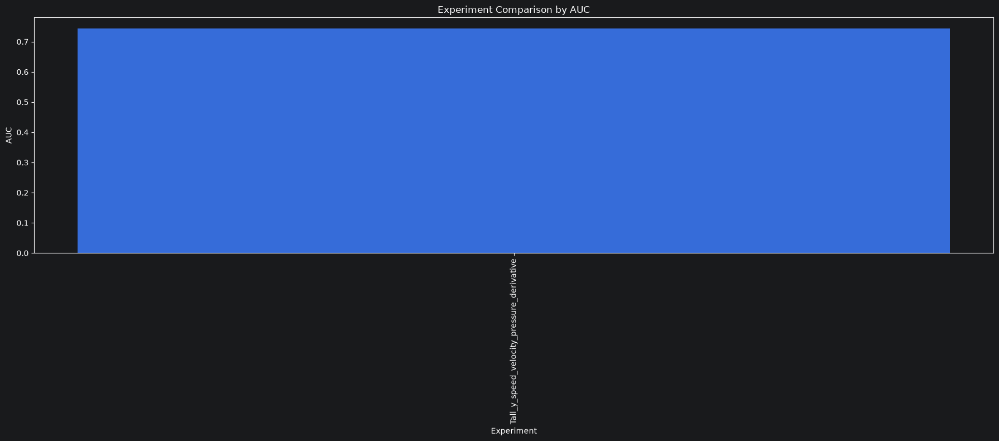

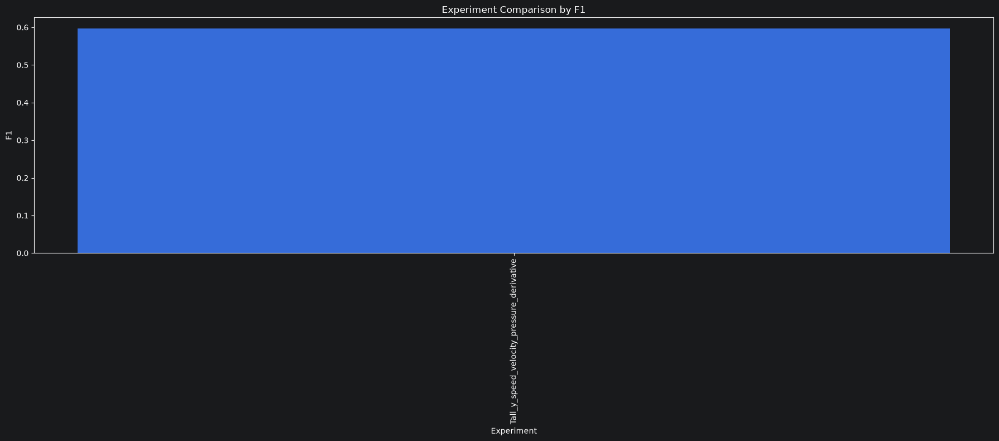


=== BEST EXPERIMENT ===
Task: all
Feature: y_speed_velocity_pressure_derivative
AUC: 0.7429
F1: 0.5963
Accuracy: 0.7067


In [16]:
# Experiments for cnn1D

task = [[1, 2, 3, 4, 5, 6, 7, 8]]
results = []

for t in task:

        runner = RunSegmentCNN(
                data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
                metadata_path=_project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"),
                tasks=t,
                feature_names=("y",),
                engineered_features=("speed", "velocity", "pressure_derivative",),
                window_size=256,
                epochs=50,
                batch_size=16,
                learning_rate=1e-3,
                regularization=1e-3,
                n_splits=5,
                normalize=True,
                device="cuda" if torch.cuda.is_available() else "cpu",
                aggregation="mean",
                output_dir=_project_path("experiments/ant/cnn1D/raw_segment(train_seg - val_no)/Task_all/y_speed_velocity_pressure_derivative"),
                training_cfg={
                    "metrics": ["accuracy", "f1", "auc", "precision", "recall", "specificity"],
                    "monitor_metric": "auc",
                    "early_stopping_patience": float("inf"),
                    "min_delta": 0.0,
                    "results_writer": "csv",
                    "save_metrics": True,
                }
        )

        summary = runner.run()

        averages = summary["averages"]

        results.append({
            "task": "all",
            "feature": "y_speed_velocity_pressure_derivative",
            "accuracy": averages["last_val_accuracy"],
            "f1": averages["last_val_f1"],
            "auc": averages["last_val_auc"],
            "precision": averages["last_val_precision"],
            "recall": averages["last_val_recall"],
            "specificity": averages["last_val_specificity"],
        })

# =========================
# DATAFRAME
# =========================

df = pd.DataFrame(results)

# Ordina per AUC
df_sorted = df.sort_values(by="auc", ascending=False)

print("\n=== TOP EXPERIMENTS ===")
print(df_sorted.head(10))

# =========================
# PLOT AUC
# =========================

labels = [
    f"T{row.task}_{row.feature}"
    for row in df_sorted.itertuples()
]

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["auc"])

plt.xticks(rotation=90)
plt.ylabel("AUC")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by AUC")

plt.tight_layout()
plt.show()

# =========================
# PLOT F1
# =========================

plt.figure(figsize=(18, 8))
plt.bar(labels, df_sorted["f1"])

plt.xticks(rotation=90)
plt.ylabel("F1")
plt.xlabel("Experiment")
plt.title("Experiment Comparison by F1")

plt.tight_layout()
plt.show()

# =========================
# BEST EXPERIMENT
# =========================

best = df_sorted.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print(f"Task: {best['task']}")
print(f"Feature: {best['feature']}")
print(f"AUC: {best['auc']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"Accuracy: {best['accuracy']:.4f}")